# Predicting listing gains in the Indian IPO market with PyTorch

When a company goes public it sells shares at a fixed issue price. On the first day of trading the market sets its own price, and the difference is the listing gain (or loss). This notebook asks whether the information available *before* listing, mainly how heavily the issue was subscribed by different classes of investor, can predict whether an IPO will list above its issue price.

It is a binary classification problem with a small tabular dataset (319 IPOs), which makes it a good test of whether a neural network is actually the right tool. The notebook builds a plain network, a regularised one with early stopping, and compares both with logistic regression.

**Data:** `Indian_IPO_Market_Data.csv`, IPOs listed in India between 2010 and 2022, originally collected from moneycontrol.

| Column | Description |
|---|---|
| `Date` | Listing date |
| `IPOName` | Name of the company |
| `Issue_Size` | Size of the issue, INR crores |
| `Subscription_QIB` | Times subscribed by qualified institutional buyers |
| `Subscription_HNI` | Times subscribed by high net worth individuals |
| `Subscription_RII` | Times subscribed by retail individual investors |
| `Subscription_Total` | Times subscribed overall |
| `Issue_Price` | Issue price, INR |
| `Listing_Gains_Percent` | Listing price relative to issue price, in percent |

This is an exercise in modelling, not investment advice.

In [1]:
import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
df = pd.read_csv("Indian_IPO_Market_Data.csv")
df.columns = df.columns.str.strip()   # the Date header has a trailing space
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%y")

print(df.shape)
display(df.head())
display(df.tail())

(319, 9)


,Date,IPOName,Issue_Size,Subscription_QIB,Subscription_HNI,Subscription_RII,Subscription_Total,Issue_Price,Listing_Gains_Percent
0,2010-02-03,Infinite Comp,189.80,48.44,106.02,11.08,43.22,165,11.82
1,2010-02-08,Jubilant Food,328.70,59.39,51.95,3.79,31.11,145,-84.21
2,2010-02-15,Syncom Health,56.25,0.99,16.60,6.25,5.17,75,17.13
3,2010-02-15,Vascon Engineer,199.80,1.12,3.65,0.62,1.22,165,-11.28
4,2010-02-19,Thangamayil,0.00,0.52,1.52,2.26,1.12,75,-5.20


,Date,IPOName,Issue_Size,Subscription_QIB,Subscription_HNI,Subscription_RII,Subscription_Total,Issue_Price,Listing_Gains_Percent
314,2022-08-26,Syrma SGS,840.13,42.42,7.13,2.84,15.59,220,42.30
315,2022-09-06,Dreamfolks Serv,562.10,27.48,14.18,24.19,23.25,326,41.92
316,2022-09-15,TMB,792.00,0.51,1.77,3.44,1.39,525,-3.15
317,2022-09-26,Harsha Engineer,755.00,113.82,40.36,12.44,47.19,330,47.24
318,2022-10-17,Electronics Mar,500.00,58.81,15.39,8.27,24.23,59,43.14


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   319 non-null    datetime64[us]
 1   IPOName                319 non-null    str           
 2   Issue_Size             319 non-null    float64       
 3   Subscription_QIB       319 non-null    float64       
 4   Subscription_HNI       319 non-null    float64       
 5   Subscription_RII       319 non-null    float64       
 6   Subscription_Total     319 non-null    float64       
 7   Issue_Price            319 non-null    int64         
 8   Listing_Gains_Percent  319 non-null    float64       
dtypes: datetime64[us](1), float64(6), int64(1), str(1)
memory usage: 26.3 KB


In [4]:
df.describe().round(2)

,Date,Issue_Size,Subscription_QIB,Subscription_HNI,Subscription_RII,Subscription_Total,Issue_Price,Listing_Gains_Percent
count,319,319.00,319.00,319.00,319.00,319.00,319.00,319.00
mean,2016-06-24 03:14:06.394984,1192.86,25.68,70.09,8.56,27.45,375.13,4.74
min,2010-02-03 00:00:00,0.00,0.00,0.00,0.00,0.00,0.00,-97.15
25%,2011-07-20 12:00:00,169.00,1.15,1.25,1.27,1.64,119.00,-11.56
50%,2017-03-17 00:00:00,496.25,4.94,5.07,3.42,4.93,250.00,1.81
75%,2021-02-02 12:00:00,1100.00,34.64,62.10,8.60,33.39,536.00,25.31
max,2022-10-17 00:00:00,21000.00,215.45,958.07,119.44,326.49,2150.00,270.40
std,NaN,2384.64,40.72,142.45,14.51,48.77,353.90,47.65


There are no missing values. Every numeric column is strongly right-skewed: the mean is well above the median, and the maxima are far out (an issue of over 21,000 crores, subscriptions of several hundred times).

## 2. Target

The firm's question is "invest or not", so the continuous gain is turned into a binary target: 1 if the IPO listed above its issue price, 0 otherwise.

In [5]:
df["Listing_Gains_Profit"] = (df["Listing_Gains_Percent"] > 0).astype(int)

target_share = df["Listing_Gains_Profit"].value_counts(normalize=True).sort_index()
print(df["Listing_Gains_Profit"].value_counts().sort_index())
print(f"\nShare of IPOs that listed at a gain: {target_share[1]:.1%}")

Listing_Gains_Profit
0    145
1    174
Name: count, dtype: int64

Share of IPOs that listed at a gain: 54.5%


The classes are close to balanced, so accuracy is a usable metric, and the benchmark any model must beat is the share of the majority class: always predicting "gain" is right a little over half the time.

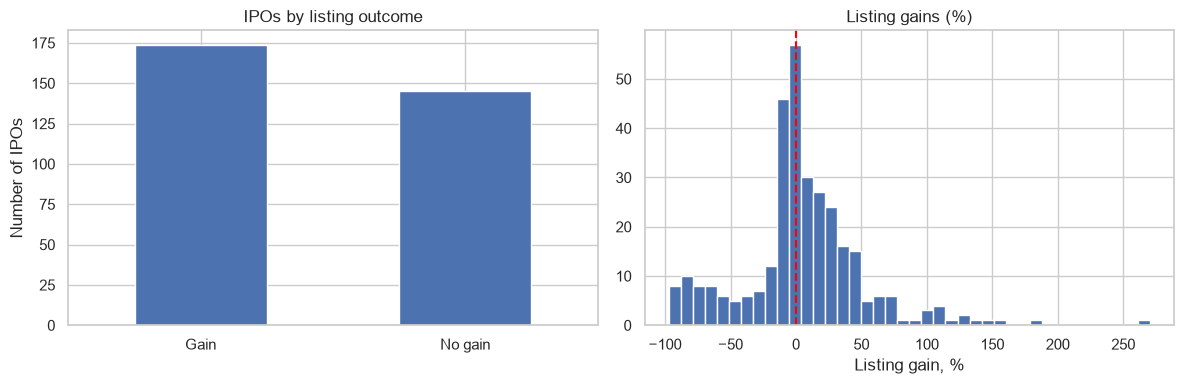

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Listing_Gains_Profit"].map({0: "No gain", 1: "Gain"}).value_counts().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("IPOs by listing outcome")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of IPOs")
axes[1].hist(df["Listing_Gains_Percent"], bins=40)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Listing gains (%)")
axes[1].set_xlabel("Listing gain, %")
plt.tight_layout()
plt.show()

## 3. Exploratory analysis

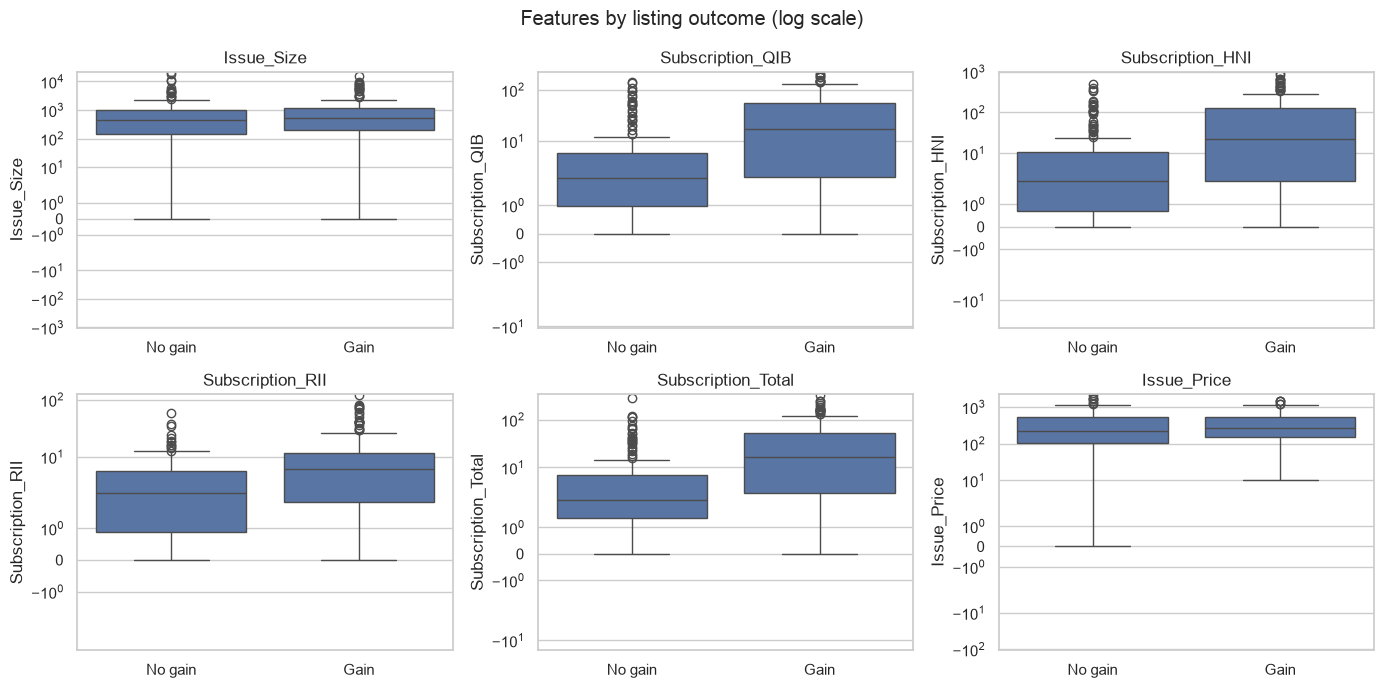

In [7]:
features = ["Issue_Size", "Subscription_QIB", "Subscription_HNI", "Subscription_RII",
            "Subscription_Total", "Issue_Price"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Listing_Gains_Profit", y=col, ax=ax)
    ax.set_yscale("symlog")
    ax.set_xlabel("")
    ax.set_xticks([0, 1], labels=["No gain", "Gain"])
    ax.set_title(col)
fig.suptitle("Features by listing outcome (log scale)")
plt.tight_layout()
plt.show()

In [8]:
df.groupby("Listing_Gains_Profit")[features].median().round(2).T.rename(columns={0: "median, no gain", 1: "median, gain"})

Listing_Gains_Profit,"median, no gain","median, gain"
Issue_Size,450.00,540.26
Subscription_QIB,1.96,16.84
Subscription_HNI,2.09,21.97
Subscription_RII,2.32,6.04
Subscription_Total,2.06,16.40
Issue_Price,220.00,272.00


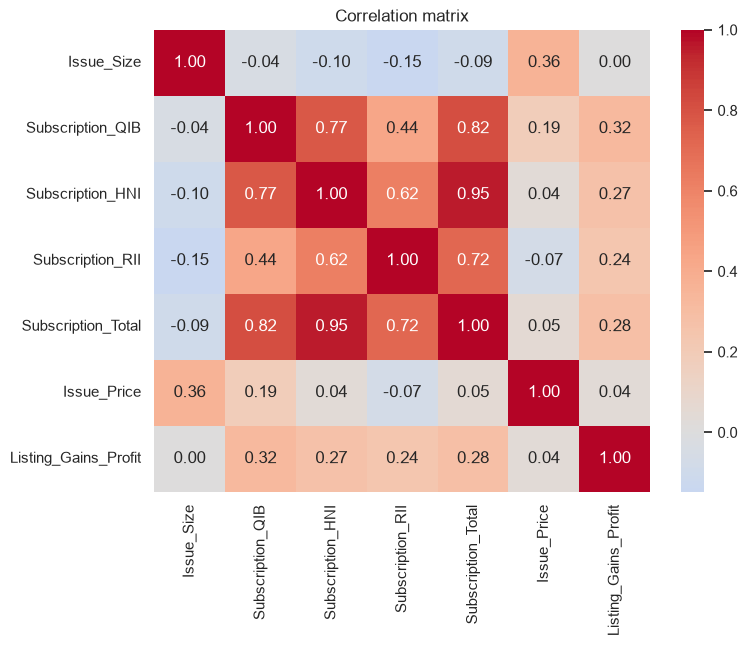

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[features + ["Listing_Gains_Profit"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

Because the features are so skewed, the linear correlation understates the relationships. A log transform, `log(1 + x)`, pulls in the long tails. Correlation of each feature with the target, raw and after the transform:

In [10]:
pd.DataFrame({
    "raw": df[features].corrwith(df["Listing_Gains_Profit"]),
    "log1p": np.log1p(df[features]).corrwith(df["Listing_Gains_Profit"]),
}).round(3).sort_values("log1p", ascending=False)

,raw,log1p
Subscription_QIB,0.323,0.386
Subscription_Total,0.283,0.383
Subscription_HNI,0.272,0.348
Subscription_RII,0.241,0.287
Issue_Price,0.040,0.122
Issue_Size,0.005,0.089


- Demand is what separates the two groups. The median IPO that listed at a gain was subscribed about 16 times overall, against about 2 times for those that did not.
- Institutional demand (`Subscription_QIB`) is the strongest single signal: a correlation of 0.32 with the target, rising to 0.39 after the log transform. HNI and total subscription are close behind, and the three are strongly correlated with each other.
- `Issue_Size` and `Issue_Price` are almost unrelated to the outcome.
- A few rows have an issue size of zero and 17 have a QIB subscription of zero. They are kept as they are; `log(1 + x)` handles zeros.

Has the success rate changed over time? If it has, the year an IPO listed carries information, and a random split will look better than a real forecast would.

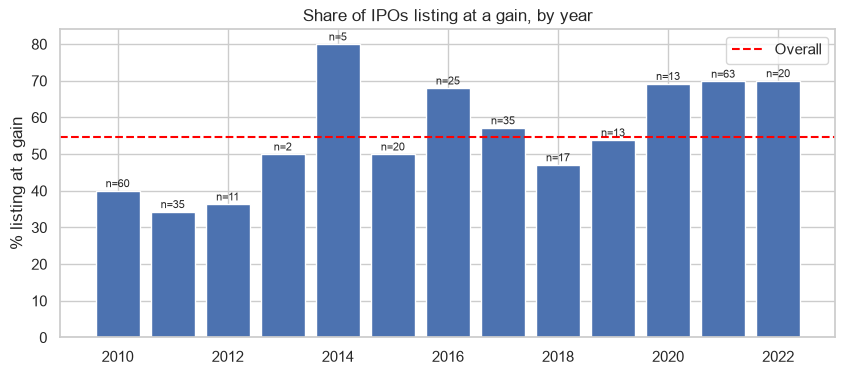

Date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
% with gain,40.0,34.0,36.0,50.0,80.0,50.0,68.0,57.0,47.0,54.0,69.0,70.0,70.0
IPOs,60.0,35.0,11.0,2.0,5.0,20.0,25.0,35.0,17.0,13.0,13.0,63.0,20.0


In [11]:
by_year = df.groupby(df["Date"].dt.year)["Listing_Gains_Profit"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_year.index, by_year["mean"] * 100)
ax.axhline(target_share[1] * 100, color="red", linestyle="--", label="Overall")
for year, row in by_year.iterrows():
    ax.text(year, row["mean"] * 100 + 1, f"n={int(row['count'])}", ha="center", fontsize=8)
ax.set_ylabel("% listing at a gain")
ax.set_title("Share of IPOs listing at a gain, by year")
ax.legend()
plt.show()

by_year.assign(mean=lambda d: (d["mean"] * 100).round(0)).rename(columns={"mean": "% with gain", "count": "IPOs"}).T

It has changed a great deal. Only 34-40% of IPOs listed at a gain in 2010-2012, against about 70% in 2020-2022. Market mood in the listing year matters at least as much as anything about the individual issue. The random split used below mixes years together, which is the standard setup for this exercise, but it means the reported accuracy is not what a model trained on the past and used on next year's IPOs would achieve.

## 4. Features, split and scaling

All six numeric features are used, log-transformed. `Date` and `IPOName` identify the IPO and are dropped, and `Listing_Gains_Percent` is the target in another form, so using it would be leakage.

The data is split 60/20/20 into training, validation and test sets, stratified on the target. The scaler is fitted on the training set only and then applied to the other two.

In [12]:
X = np.log1p(df[features])
y = df["Listing_Gains_Profit"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} n={len(part):<4} share with gain={part.mean():.3f}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

train       n=191  share with gain=0.545
validation  n=64   share with gain=0.547
test        n=64   share with gain=0.547


## 5. Tensors and data loaders

In [13]:
def to_tensor(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32)


X_train_t, X_val_t, X_test_t = map(to_tensor, (X_train_scaled, X_val_scaled, X_test_scaled))
y_train_t, y_val_t, y_test_t = map(to_tensor, (y_train, y_val, y_test))

BATCH_SIZE = 16


def make_loader(X_tensor, y_tensor, seed=SEED):
    return DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))


train_loader = make_loader(X_train_t, y_train_t)

batch_features, batch_targets = next(iter(train_loader))
print("Batch shapes:", tuple(batch_features.shape), tuple(batch_targets.shape))
print("Training batches per epoch:", len(train_loader))

Batch shapes: (16, 6) (16,)
Training batches per epoch: 12


## 6. A plain network

Three hidden layers that narrow towards the output (32, 16, 8). The last layer returns a raw score (a logit); the sigmoid is applied inside the loss function, `BCEWithLogitsLoss`, which is numerically more stable than a separate sigmoid followed by `BCELoss`.

In [14]:
def build_plain_model(n_features):
    return nn.Sequential(
        nn.Linear(n_features, 32), nn.ReLU(),
        nn.Linear(32, 16), nn.ReLU(),
        nn.Linear(16, 8), nn.ReLU(),
        nn.Linear(8, 1),
    )


set_seed()
model = build_plain_model(X_train_t.shape[1])
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=6, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=8, bias=True)
  (5): ReLU()
  (6): Linear(in_features=8, out_features=1, bias=True)
)
Trainable parameters: 897


One training function is used for every model. After each epoch it records the loss and accuracy on the training and validation sets. If `patience` is given, training stops when the validation loss has not improved for that many epochs, and the weights from the best epoch are restored.

In [15]:
criterion = nn.BCEWithLogitsLoss()


def evaluate(model, X, y):
    """Loss and accuracy (%) of a model on a full dataset."""
    model.eval()
    with torch.no_grad():
        logits = model(X).squeeze(1)
        loss = criterion(logits, y).item()
        accuracy = ((torch.sigmoid(logits) > 0.5).float() == y).float().mean().item() * 100
    return loss, accuracy


def train(model, loader, train_set, val_set, lr=0.001, max_epochs=100, patience=None, weight_decay=0.0):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_state, best_epoch, waited = float("inf"), None, 0, 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        for batch_features, batch_targets in loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_features).squeeze(1), batch_targets)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, *train_set)
        val_loss, val_acc = evaluate(model, *val_set)
        for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[key].append(value)

        if patience is not None:
            if val_loss < best_val_loss - 1e-4:
                best_val_loss, best_state, best_epoch, waited = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
            else:
                waited += 1
                if waited >= patience:
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch if patience is not None else len(history["val_loss"])
    return history


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history["train_loss"]) + 1)
    axes[0].plot(epochs, history["train_loss"], label="Training")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_ylabel("Loss")
    axes[1].plot(epochs, history["train_acc"], label="Training")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_ylabel("Accuracy (%)")
    for ax in axes:
        ax.axvline(history["best_epoch"], color="grey", linestyle=":", label="Weights kept")
        ax.set_xlabel("Epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

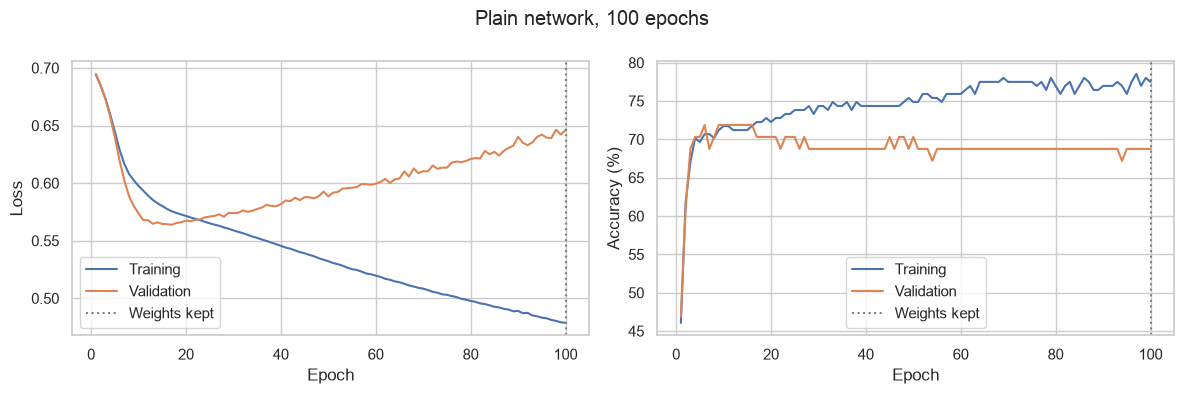

Training:   loss 0.479, accuracy 77.5%
Validation: loss 0.646, accuracy 68.8%
Lowest validation loss was at epoch 17


In [16]:
set_seed()
model = build_plain_model(X_train_t.shape[1])
train_set, val_set = (X_train_t, y_train_t), (X_val_t, y_val_t)
plain_history = train(model, train_loader, train_set, val_set, lr=0.001, max_epochs=100)
plot_history(plain_history, "Plain network, 100 epochs")

plain_train = evaluate(model, X_train_t, y_train_t)
plain_val = evaluate(model, X_val_t, y_val_t)
print(f"Training:   loss {plain_train[0]:.3f}, accuracy {plain_train[1]:.1f}%")
print(f"Validation: loss {plain_val[0]:.3f}, accuracy {plain_val[1]:.1f}%")
print(f"Lowest validation loss was at epoch {int(np.argmin(plain_history['val_loss'])) + 1}")

The network overfits. Training loss keeps falling for all 100 epochs, but validation loss reaches its minimum at epoch 17 and climbs from there. By the end the model is 77.5% accurate on the training set and 68.8% on the validation set: it is memorising 191 IPOs.

## 7. Regularised network with early stopping

The same shape of network with three additions:

- **Batch normalisation** after each hidden linear layer
- **Dropout** after each activation, heavier in the wider layers
- **Early stopping** on the validation loss, keeping the weights from the best epoch

A small weight decay is also applied through the optimiser.

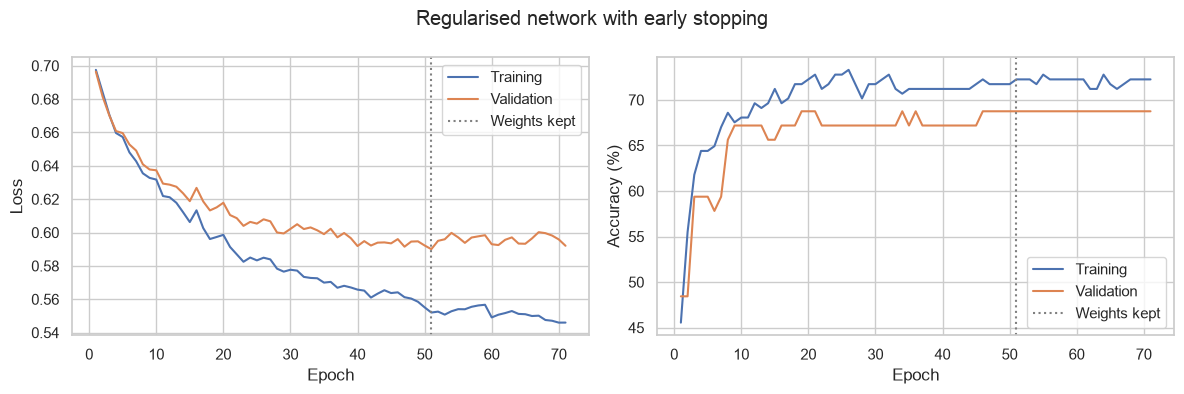

Stopped after 71 epochs; weights kept from epoch 51
Training:   loss 0.552, accuracy 72.3%
Validation: loss 0.590, accuracy 68.8%


In [17]:
def build_regularised_model(n_features):
    return nn.Sequential(
        nn.Linear(n_features, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(32, 16), nn.BatchNorm1d(16), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(16, 8), nn.BatchNorm1d(8), nn.ReLU(), nn.Dropout(0.1),
        nn.Linear(8, 1),
    )


set_seed()
reg_model = build_regularised_model(X_train_t.shape[1])
reg_history = train(reg_model, train_loader, train_set, val_set, lr=0.001, max_epochs=200, patience=20, weight_decay=1e-4)
plot_history(reg_history, "Regularised network with early stopping")

reg_train = evaluate(reg_model, X_train_t, y_train_t)
reg_val = evaluate(reg_model, X_val_t, y_val_t)
print(f"Stopped after {len(reg_history['val_loss'])} epochs; weights kept from epoch {reg_history['best_epoch']}")
print(f"Training:   loss {reg_train[0]:.3f}, accuracy {reg_train[1]:.1f}%")
print(f"Validation: loss {reg_val[0]:.3f}, accuracy {reg_val[1]:.1f}%")

In [18]:
pd.DataFrame({
    "plain network": {"train accuracy": plain_train[1], "validation accuracy": plain_val[1],
                      "gap": plain_train[1] - plain_val[1], "validation loss": plain_val[0]},
    "regularised network": {"train accuracy": reg_train[1], "validation accuracy": reg_val[1],
                            "gap": reg_train[1] - reg_val[1], "validation loss": reg_val[0]},
}).round(3)

,plain network,regularised network
train accuracy,77.487,72.251
validation accuracy,68.750,68.750
gap,8.737,3.501
validation loss,0.646,0.590


Regularisation does what it should. The gap between training and validation accuracy shrinks from 8.7 points to 3.5, and validation loss improves from 0.646 to 0.590. Validation accuracy itself is unchanged at 68.8%: the model is better calibrated and less overfitted, but it does not classify more validation IPOs correctly.

## 8. A simpler model for comparison

With six features and under 200 training rows, a linear model is a serious competitor. Logistic regression on the same scaled features:

In [19]:
logreg = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
print(f"Logistic regression: train accuracy {logreg.score(X_train_scaled, y_train) * 100:.1f}%, "
      f"validation accuracy {logreg.score(X_val_scaled, y_val) * 100:.1f}%")
pd.Series(logreg.coef_[0], index=features).sort_values().round(3)

Logistic regression: train accuracy 69.1%, validation accuracy 73.4%


Subscription_RII     -0.007
Issue_Price           0.007
Issue_Size            0.019
Subscription_HNI      0.045
Subscription_Total    0.239
Subscription_QIB      0.652
dtype: float64

Logistic regression scores 73.4% on the validation set, higher than either network, with almost all of its weight on QIB subscription.

## 9. Test-set evaluation

The test set has not been used for any decision so far. Each model is scored on it once, at the default 0.5 threshold.

In [20]:
def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X).squeeze(1)).numpy()


test_probabilities = {
    "Plain network": predict_proba(model, X_test_t),
    "Regularised network": predict_proba(reg_model, X_test_t),
    "Logistic regression": logreg.predict_proba(X_test_scaled)[:, 1],
}

rows = {}
for name, proba in test_probabilities.items():
    predicted = (proba > 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    rows[name] = {
        "accuracy": (tp + tn) / len(y_test),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted),
        "roc_auc": roc_auc_score(y_test, proba),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

test_results = pd.DataFrame(rows).T
test_results[["TN", "FP", "FN", "TP"]] = test_results[["TN", "FP", "FN", "TP"]].astype(int)
print(f"Majority-class baseline accuracy on the test set: {max(y_test.mean(), 1 - y_test.mean()):.3f}")
test_results.round(3)

Majority-class baseline accuracy on the test set: 0.547


,accuracy,precision,recall,roc_auc,TN,FP,FN,TP
Plain network,0.578,0.654,0.486,0.594,20,9,18,17
Regularised network,0.594,0.696,0.457,0.611,22,7,19,16
Logistic regression,0.609,0.708,0.486,0.662,22,7,18,17


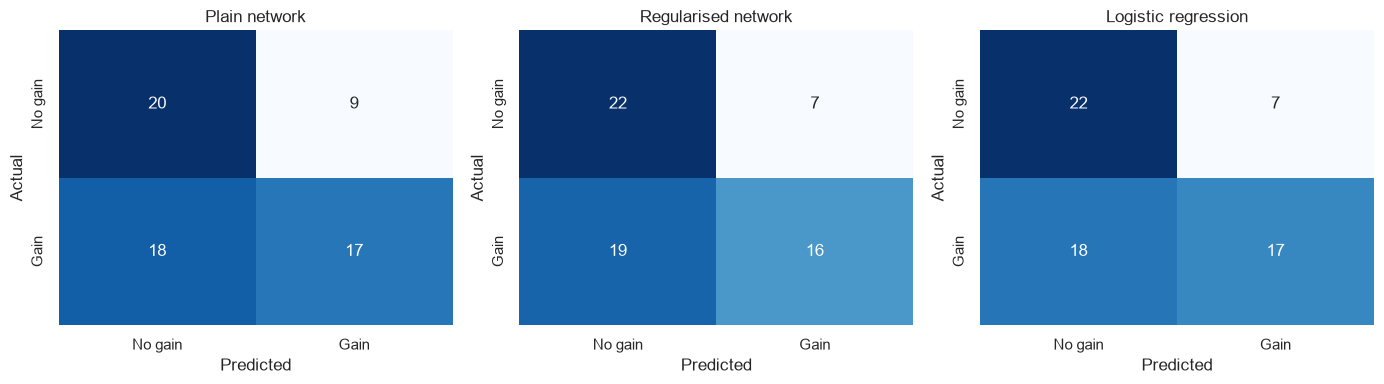

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, proba) in zip(axes, test_probabilities.items()):
    sns.heatmap(confusion_matrix(y_test, (proba > 0.5).astype(int)), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No gain", "Gain"], yticklabels=["No gain", "Gain"], ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name)
plt.tight_layout()
plt.show()

On this test set all three models land between 58% and 61%, only a little above the 54.7% majority-class baseline, and well below their validation scores.

The pattern of errors is the same for each model. Precision is around 0.65-0.71 and recall is below 0.5: when a model predicts a gain it is right about two times in three, but it misses half of the IPOs that did gain. In business terms:

- A **false positive** is money put into an IPO that lists flat or down. That is a realised loss.
- A **false negative** is an IPO the firm skipped that would have made money. That is a missed opportunity.

For a cautious investor the first is worse, so a model that is selective (higher precision, lower recall) errs in the safer direction. Even so, about 30% of the model's "invest" calls here were wrong.

## 10. How much of this is luck?

The test set has 64 IPOs, so one misclassified IPO moves accuracy by about 1.6 points, and a different random split or initialisation could reorder the models. To see how stable the comparison is, the whole procedure (split, scale, train, test) is repeated for 20 different seeds.

In [22]:
def run_once(seed):
    Xtr, Xtmp, ytr, ytmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=seed)
    Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=0.5, stratify=ytmp, random_state=seed)
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xva_s, Xte_s = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)

    Xtr_t, Xva_t, Xte_t = map(to_tensor, (Xtr_s, Xva_s, Xte_s))
    ytr_t, yva_t = map(to_tensor, (ytr, yva))
    loader = make_loader(Xtr_t, ytr_t, seed)

    set_seed(seed)
    plain = build_plain_model(X.shape[1])
    train(plain, loader, (Xtr_t, ytr_t), (Xva_t, yva_t), max_epochs=100)
    set_seed(seed)
    regularised = build_regularised_model(X.shape[1])
    train(regularised, loader, (Xtr_t, ytr_t), (Xva_t, yva_t), max_epochs=200, patience=20, weight_decay=1e-4)
    linear = LogisticRegression(max_iter=1000).fit(Xtr_s, ytr)

    accuracy = lambda proba: ((proba > 0.5).astype(int) == yte.to_numpy()).mean() * 100
    return {
        "Plain network": accuracy(predict_proba(plain, Xte_t)),
        "Regularised network": accuracy(predict_proba(regularised, Xte_t)),
        "Logistic regression": accuracy(linear.predict_proba(Xte_s)[:, 1]),
        "Majority class": max(yte.mean(), 1 - yte.mean()) * 100,
    }


repeats = pd.DataFrame([run_once(seed) for seed in range(20)])
repeats.agg(["mean", "std", "min", "max"]).round(1).T

,mean,std,min,max
Plain network,64.9,6.0,56.2,78.1
Regularised network,66.5,5.7,54.7,78.1
Logistic regression,67.0,5.5,57.8,78.1
Majority class,54.7,0.0,54.7,54.7


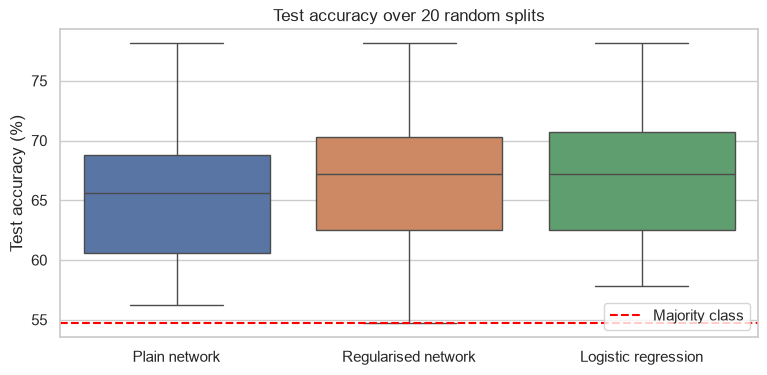

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=repeats.drop(columns="Majority class"), ax=ax)
ax.axhline(repeats["Majority class"].mean(), color="red", linestyle="--", label="Majority class")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Test accuracy over 20 random splits")
ax.legend()
plt.show()

Averaged over 20 splits, the models reach 65-67% test accuracy against a 54.7% baseline, with a standard deviation of about 6 points. Results for a single split range from the mid-50s to 78%, so the split used above was at the unlucky end, and the differences between the three models (about 2 points) are well inside the noise.

## Conclusions

- **There is real but modest signal.** Subscription data, above all institutional (QIB) demand, predicts a listing gain about 10-12 points better than always guessing "gain".
- **Regularisation fixed the overfitting, not the accuracy.** Batch normalisation, dropout and early stopping cut the train/validation gap from 8.7 to 3.5 points, but did not make the network more accurate on unseen IPOs.
- **A neural network is not needed here.** Logistic regression matches or beats both networks on average. With six correlated features and 319 rows there is nothing for extra capacity to learn.
- **A single test score on 64 rows is not trustworthy.** The same pipeline gives anything from 55% to 78% depending on the split. Repeating the split, or cross-validating, is what makes the comparison meaningful.
- **The honest caveat is time.** The share of IPOs listing at a gain doubled between 2010-2012 and 2020-2022. A random split lets the model see IPOs from every year; a real forecast would have to be trained on earlier years and tested on later ones, and would need some measure of market conditions at the time of listing.

Next steps: a time-ordered split, features describing the market at the listing date (for example recent index returns), and choosing the decision threshold on the validation set to match the firm's tolerance for false positives.